In [2]:
using VoronoiMeshes,TensorsLite, TensorsLiteGeometry, ImmutableVectors, LinearAlgebra, NCDatasets, MPASTools
using StaticArrays, SparseArrays
using CairoMakie, Printf, DataFrames, CSV, JLD2    
include("../juliaDEC.jl")

plot_cochain

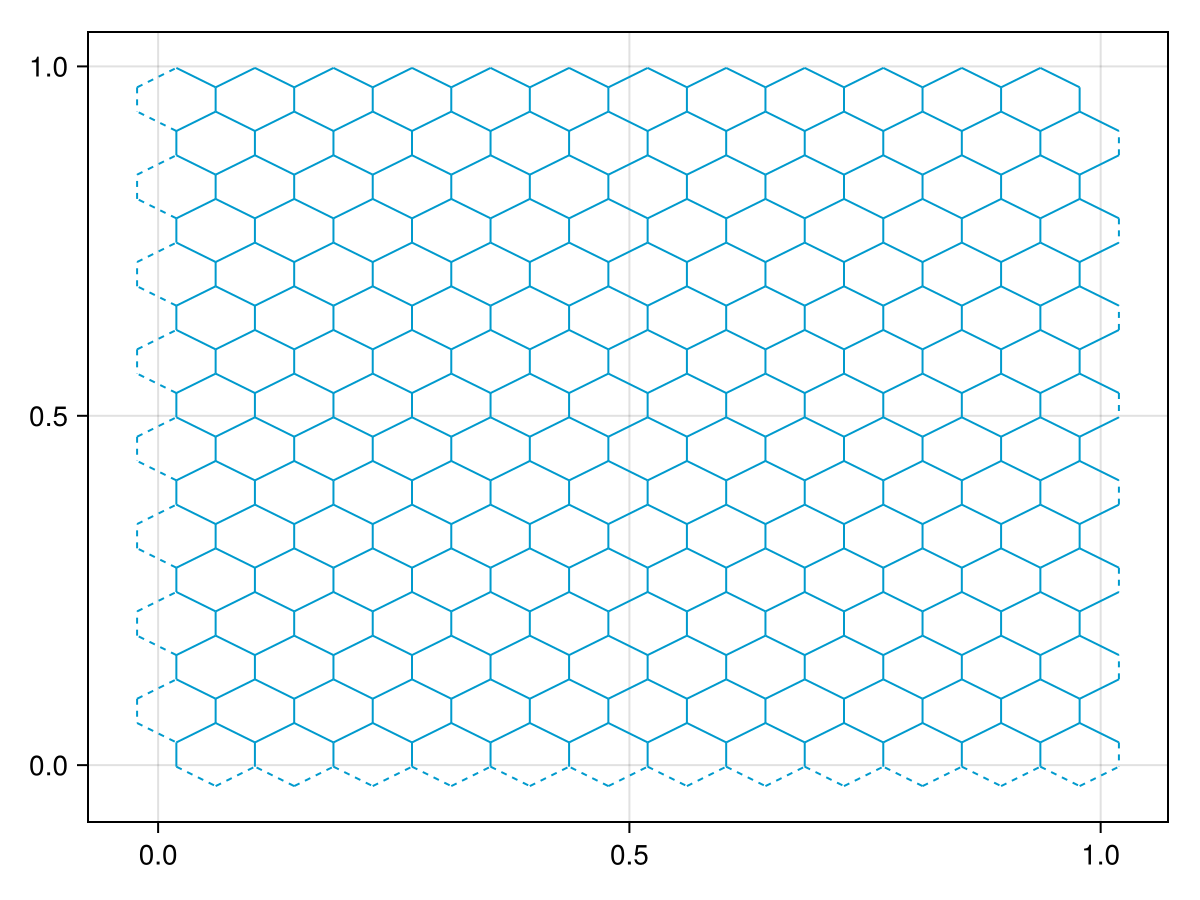

In [95]:
mesh = VoronoiMesh("../meshes/mesh3_regular.nc")
plotmesh(mesh)

Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 10, and max time of 4.0 minutes
Elapsed time: 0.0 minutes. Lloyd iteration number 10 Stopped Lloyd's algorithm at iteration 10, after 0.0 minutes


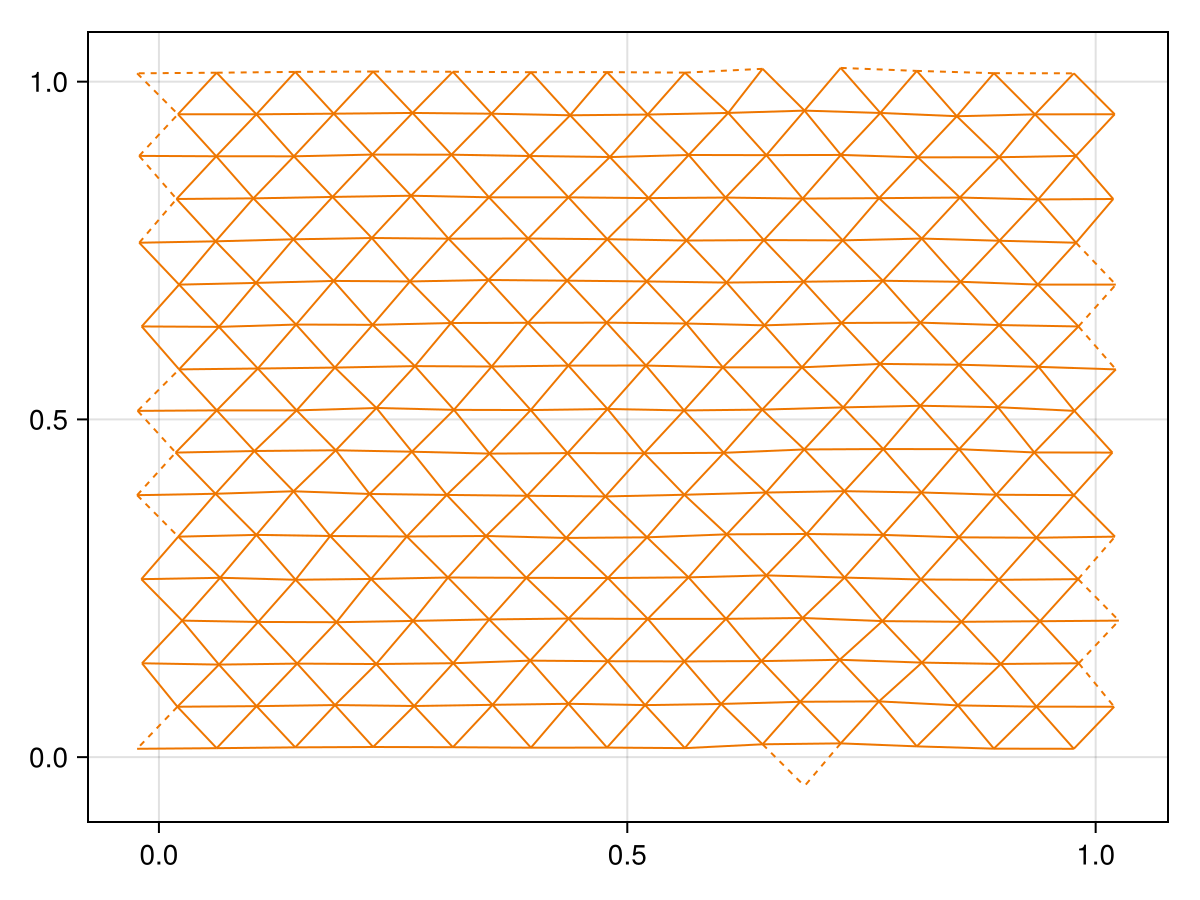

In [114]:
base_mesh = VoronoiMesh("../meshes/mesh3_regular.nc")
new_voronoi_generators = copy(base_mesh.cells.position)

function normalize_points!(points)
    x_max = maximum(points.x)
    y_max = maximum(points.y)
    for i in eachindex(points)
        p = (points[i].x ./ x_max)*𝐢 + (points[i].y ./ y_max)*𝐣
        points[i] = p
    end
    return points
end

#Aqui você define a deformação que você quiser
function deform_points!(points, base_displacement)
    for i in eachindex(points)
#       esta parte gera um número entre -1 e 1
#             |------------|
        dp = ((2*rand() - 1)*base_displacement)*𝐢 + ((2*rand() - 1)*base_displacement)*𝐣
        points[i] = points[i] + dp
    end
    return points
end

#aplica a deformação                        #isto aqui é a distância mínima entre células de voronoi
deform_points!(new_voronoi_generators, 0.2*minimum(base_mesh.edges.lengthDual))
new_mesh = VoronoiMesh(new_voronoi_generators, base_mesh.x_period, base_mesh.y_period; max_iter = 10)

plotdualmesh(new_mesh)

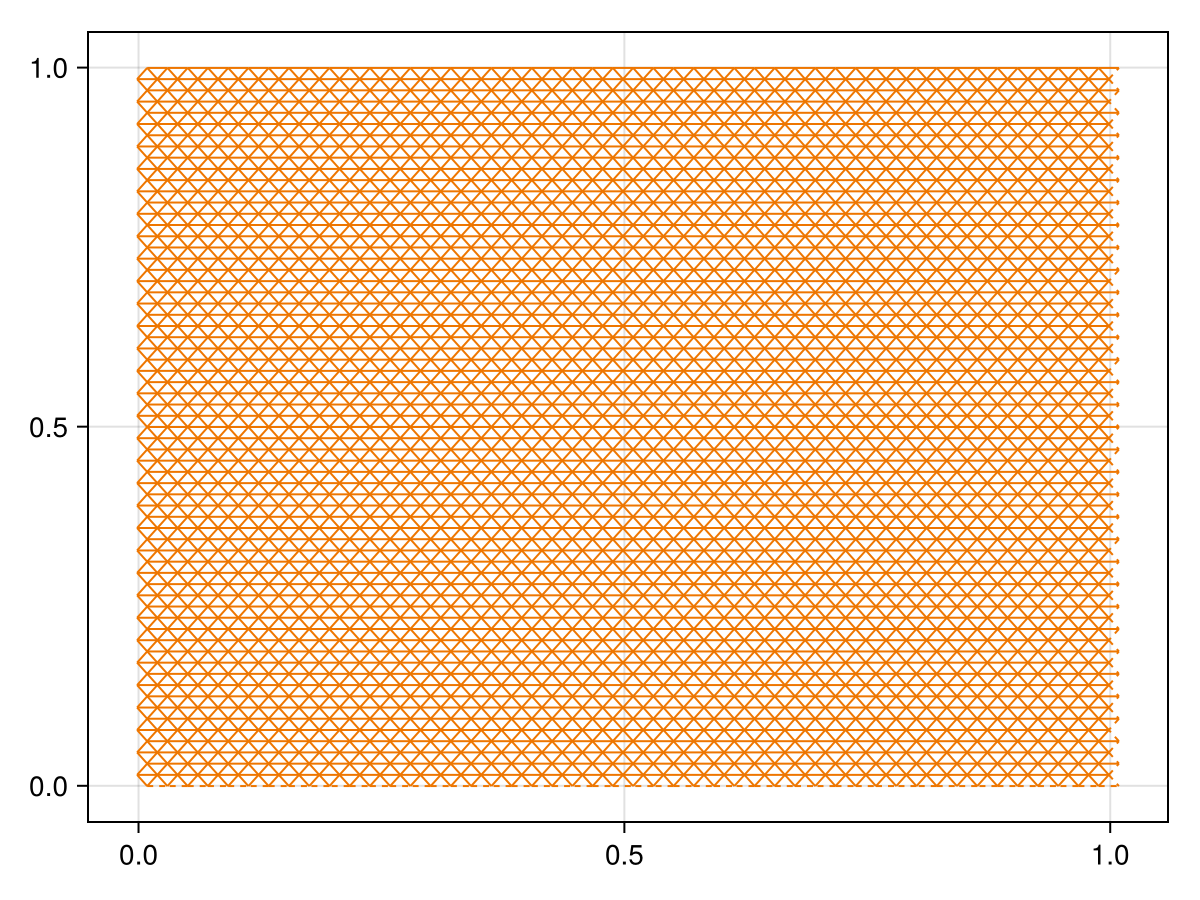

In [94]:
base_mesh = VoronoiMesh("../meshes/mesh5_regular.nc")
plotdualmesh(base_mesh)


In [64]:
new_voronoi_generators 

1080-element Vec2DxyArray{Float64, 1}:
 [262.4999999999997, 262.5000000000025, 𝟎]
 [8662.5, 262.50000000000153, 𝟎]
 [17062.499999999996, 262.50000000000057, 𝟎]
 [25462.5, 262.50000000000205, 𝟎]
 [33862.5, 262.5000000000001, 𝟎]
 [42262.50000000001, 262.50000000000216, 𝟎]
 [50662.500000000015, 262.49999999999966, 𝟎]
 [59062.5, 262.50000000000034, 𝟎]
 [67462.5, 262.5000000000033, 𝟎]
 [75862.5, 262.5000000000023, 𝟎]
 ⋮
 [36662.50000000001, 58459.40713431428, 𝟎]
 [39462.5, 14811.726783578568, 𝟎]
 [18462.5, 51184.793742524984, 𝟎]
 [74462.5, 7537.113391789284, 𝟎]
 [49262.5, 31785.824697753567, 𝟎]
 [82862.5, 2687.3711305964284, 𝟎]
 [57662.5, 46335.05148133213, 𝟎]
 [19862.500000000004, 34210.69582835, 𝟎]
 [68862.5, 80283.24730968213, 𝟎]